<div style="background:#0B2545;color:white;padding:18px 22px;border-radius:8px">
<div style="font-size:12px;letter-spacing:2px;opacity:.8">DATABANK ACADEMY · PROGRAMA EJECUTIVO EN GESTIÓN INTEGRAL DEL RIESGO DE CRÉDITO MINORISTA</div>
<div style="font-size:24px;font-weight:700;margin-top:6px">Módulo 3 · Sesión 3: Weight of Evidence, Information Value y binning óptimo con optbinning y fastwoe</div>
<div style="font-size:14px;margin-top:4px;opacity:.9">Laboratorio: WoE/IV manual, tendencias y restricciones, códigos especiales, 2D, BinningProcess, WoE con IC, IV con test, WoE condicional</div>
</div>

## Objetivos de la sesión (2 horas)

1. Calcular e interpretar **Weight of Evidence (WoE)** e **Information Value (IV)**.
2. Usar **optbinning** con sus funcionalidades avanzadas: tendencias monotónicas (incluidas *peak* y *valley*), códigos especiales, faltantes, restricciones estadísticas, solvers CP/MIP, categóricas de alta cardinalidad, binning 2D, `BinningProcess` con criterios de selección y análisis de calidad.
3. Usar **fastwoe** para **inferencia sobre el WoE**: errores estándar, intervalos de confianza, IV con test de significancia, sesgo de ruido, **WoE condicional** (regla de la cadena de Good), reducción de cardinalidad e intervalos para la predicción.
4. Evaluar la **estabilidad** de los tramos fuera de tiempo y comparar los enfoques.

| Bloque | Tiempo | Contenido |
|---|---|---|
| 1 | 15 min | WoE e IV: definición y cálculo manual |
| 2 | 40 min | optbinning: binning óptimo con restricciones |
| 3 | 35 min | fastwoe: WoE con inferencia estadística |
| 4 | 20 min | Estabilidad y comparación de enfoques |
| 5 | 10 min | Ejercicios |

> **Instalación:** `pip install optbinning fastwoe`. optbinning usa OR-Tools (solver CP/MIP) y fastwoe usa scikit-learn.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .3, "font.size": 11})
AZUL, ROJO, VERDE, GRIS, ORO = "#0B2545", "#C8102E", "#2E8B57", "#8D99AE", "#E0A100"
DATA = Path("../datos")

import warnings; warnings.filterwarnings("ignore")
from optbinning import OptimalBinning, OptimalBinning2D, BinningProcess
from fastwoe import FastWoe, WoePreprocessor
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
app = pd.read_csv(DATA / "hc_application_sintetico.csv").drop_duplicates()
app["EDAD"] = -app.DAYS_BIRTH / 365.25
app["RCI"] = app.AMT_ANNUITY / (app.AMT_INCOME_TOTAL / 12)
app["OCCUPATION_TYPE"] = app.OCCUPATION_TYPE.fillna("Sin dato")
dev = app[app.FECHA_SOLICITUD < "2025-01"].copy(); oot = app[app.FECHA_SOLICITUD >= "2025-01"].copy()
y_dev, y_oot = dev.TARGET.values, oot.TARGET.values
print(f"desarrollo: {len(dev):,} | fuera de tiempo: {len(oot):,}")

desarrollo: 45,092 | fuera de tiempo: 14,908


## 1. WoE e IV
Para un tramo (bin) $i$ de una variable, con $g_i$ y $b_i$ la proporción de **buenos** y de **malos** de toda la cartera que cae en ese tramo:
$$WoE_i = \ln\frac{g_i}{b_i} \qquad IV = \sum_i (g_i - b_i)\, WoE_i$$

- WoE > 0: el tramo tiene **menos** riesgo que el promedio; WoE < 0: más riesgo (convención de optbinning y de la mayoría de textos de scoring).
- El IV es una divergencia simétrica (Kullback-Leibler) entre la distribución de buenos y de malos.

| IV | Poder predictivo (regla práctica, Siddiqi) |
|---|---|
| < 0,02 | Ninguno |
| 0,02 – 0,10 | Débil |
| 0,10 – 0,30 | Medio |
| 0,30 – 0,50 | Fuerte |
| > 0,50 | Sospechoso: revisar fuga de información |

In [2]:
def woe_iv(df, var, target="TARGET"):
    t = df.groupby(var, observed=True)[target].agg(n="size", malos="sum")
    t["buenos"] = t.n - t.malos
    t["%buenos"] = t.buenos / t.buenos.sum(); t["%malos"] = t.malos / t.malos.sum()
    t["tasa_malos"] = t.malos / t.n
    t["WoE"] = np.log(t["%buenos"] / t["%malos"])
    t["IV_tramo"] = (t["%buenos"] - t["%malos"]) * t.WoE
    return t
t = woe_iv(dev, "NAME_INCOME_TYPE")
display(t.style.format({"%buenos": "{:.1%}", "%malos": "{:.1%}", "tasa_malos": "{:.2%}", "WoE": "{:+.3f}", "IV_tramo": "{:.4f}"}))
print(f"IV total de NAME_INCOME_TYPE = {t.IV_tramo.sum():.4f}")

,n,malos,buenos,%buenos,%malos,tasa_malos,WoE,IV_tramo
NAME_INCOME_TYPE,,,,,,,,
Commercial associate,10594,900,9694,23.5%,23.0%,8.50%,+0.024,0.0001
Pensioner,8064,312,7752,18.8%,8.0%,3.87%,+0.860,0.0934
State servant,3225,192,3033,7.4%,4.9%,5.95%,+0.407,0.0100
Unemployed,25,1,24,0.1%,0.0%,4.00%,+0.826,0.0003
Working,23184,2512,20672,50.2%,64.1%,10.84%,-0.245,0.0341


IV total de NAME_INCOME_TYPE = 0.1380


**¿Por qué discretizar y usar WoE en un scorecard?** Captura **no linealidades** manteniendo una logística simple; trata **faltantes y códigos especiales** como tramos propios; neutraliza **outliers**; permite imponer **monotonicidad** (requisito de explicabilidad); y produce una tabla de puntos fácil de auditar. El costo: se pierde información dentro de cada tramo y aparecen saltos en los cortes.

## 2. optbinning: binning óptimo con restricciones
`OptimalBinning` formula la discretización como un **problema de optimización** (programación con restricciones o entera mixta): elige los cortes que **maximizan el IV** (u otra divergencia) sujeto a restricciones de tamaño mínimo, número de tramos, significancia entre tramos adyacentes y forma de la tendencia.

### 2.1 Tendencias monotónicas

,estado,n_tramos,IV
monotonic_trend,,,
auto_asc_desc,OPTIMAL,11,0.1744
descending,OPTIMAL,11,0.1744
peak,OPTIMAL,11,0.1744
valley,OPTIMAL,11,0.1744
convex,OPTIMAL,4,0.1580
ascending,OPTIMAL,1,0.0000


,Bin,Count,Count (%),Event rate,WoE,IV
0,"(-inf, 25.16)",3695,0.0819,0.1480,-0.6024,0.0381
1,"[25.16, 28.05)",2589,0.0574,0.1336,-0.4834,0.0164
2,"[28.05, 32.86)",4434,0.0983,0.1204,-0.3642,0.0152
3,"[32.86, 36.71)",3537,0.0784,0.1060,-0.2205,0.0042
4,"[36.71, 39.65)",2680,0.0594,0.0981,-0.1344,0.0011
5,"[39.65, 43.36)",3266,0.0724,0.0882,-0.0165,0.0000
6,"[43.36, 51.80)",7622,0.1690,0.0813,0.0717,0.0008
7,"[51.80, 54.65)",2588,0.0574,0.0761,0.1438,0.0011
8,"[54.65, 58.63)",5746,0.1274,0.0606,0.3891,0.0164
9,"[58.63, 62.76)",5301,0.1176,0.0515,0.5608,0.0294


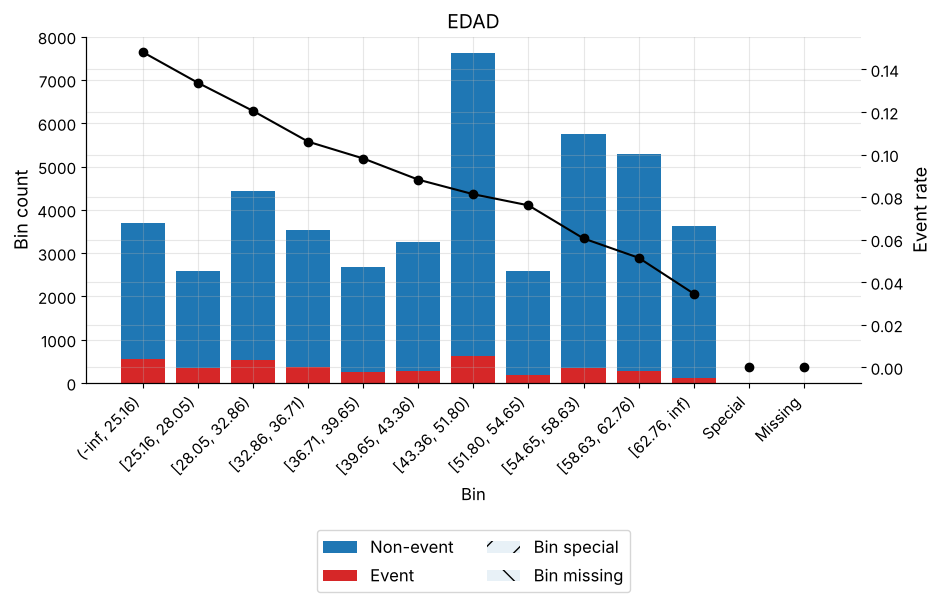

In [3]:
res = []
for tendencia in ["auto_asc_desc", "descending", "peak", "valley", "convex", "ascending"]:
    ob = OptimalBinning(name="EDAD", dtype="numerical", solver="cp", monotonic_trend=tendencia, min_bin_size=0.05)
    ob.fit(dev.EDAD.values, y_dev)
    bt = ob.binning_table.build()
    res.append({"monotonic_trend": tendencia, "estado": ob.status, "n_tramos": len(ob.splits) + 1, "IV": bt.loc["Totals", "IV"]})
display(pd.DataFrame(res).set_index("monotonic_trend").style.format({"IV": "{:.4f}"}))

ob_edad = OptimalBinning(name="EDAD", dtype="numerical", solver="cp", monotonic_trend="descending", min_bin_size=0.05)
ob_edad.fit(dev.EDAD.values, y_dev)
display(ob_edad.binning_table.build()[["Bin", "Count", "Count (%)", "Event rate", "WoE", "IV"]])
ob_edad.binning_table.plot(metric="event_rate", show_bin_labels=True)

**Lectura:** como el riesgo ya baja con la edad, `auto_asc_desc`, `descending`, `peak` y `valley` llegan a la misma solución (una curva monótona es un caso particular de pico o valle). `convex` obliga a una curvatura y pierde IV; `ascending`, la tendencia **equivocada**, destruye casi todo el poder predictivo: el solver respeta la restricción aunque sea absurda, así que la tendencia debe venir del negocio y de los datos. `peak`/`valley` permiten un único máximo o mínimo (útil, por ejemplo, para antigüedad o uso de línea), y `convex`/`concave` imponen curvatura. Una tendencia impuesta por negocio puede costar un poco de IV, pero gana estabilidad y explicabilidad.

### 2.2 Códigos especiales, faltantes y restricciones estadísticas
`DAYS_EMPLOYED = 365243` es un código especial (pensionistas). Si no se declara, contamina el último tramo.

In [4]:
sin_especial = OptimalBinning(name="DAYS_EMPLOYED", dtype="numerical", monotonic_trend="auto_asc_desc").fit(dev.DAYS_EMPLOYED.values, y_dev)
con_especial = OptimalBinning(name="DAYS_EMPLOYED", dtype="numerical", monotonic_trend="auto_asc_desc",
                              special_codes=[365243], min_bin_size=0.05, max_pvalue=0.05, max_pvalue_policy="consecutive").fit(dev.DAYS_EMPLOYED.values, y_dev)
print("SIN declarar el código especial:"); display(sin_especial.binning_table.build()[["Bin", "Count", "Event rate", "WoE"]].tail(4))
print("CON special_codes=[365243], tamaño mínimo 5 % y p-valor máximo 0,05 entre tramos consecutivos:")
display(con_especial.binning_table.build()[["Bin", "Count", "Event rate", "WoE", "IV"]])
ob_ext1 = OptimalBinning(name="EXT_SOURCE_1", dtype="numerical", monotonic_trend="descending").fit(dev.EXT_SOURCE_1.values, y_dev)
print("EXT_SOURCE_1 (56 % faltante): el faltante es un tramo propio con su propio WoE")
display(ob_ext1.binning_table.build()[["Bin", "Count (%)", "Event rate", "WoE"]].tail(3))

SIN declarar el código especial:


,Bin,Count,Event rate,WoE
1,"[-33.50, inf)",8119,0.0388,0.8573
2,Special,0,0.0000,0.0000
3,Missing,0,0.0000,0.0000
Totals,,45092,0.0869,


CON special_codes=[365243], tamaño mínimo 5 % y p-valor máximo 0,05 entre tramos consecutivos:


,Bin,Count,Event rate,WoE,IV
0,"(-inf, -4524.50)",3398,0.0456,0.6883,0.0270
1,"[-4524.50, -2976.50)",5664,0.0745,0.1669,0.0033
2,"[-2976.50, -1297.50)",14994,0.1002,-0.1572,0.0088
3,"[-1297.50, inf)",12972,0.1176,-0.3375,0.0377
4,Special,8064,0.0387,0.8602,0.0934
5,Missing,0,0.0000,0.0000,0.0000
Totals,,45092,0.0869,,0.1701


EXT_SOURCE_1 (56 % faltante): el faltante es un tramo propio con su propio WoE


,Bin,Count (%),Event rate,WoE
7,Special,0.0000,0.0000,0.0000
8,Missing,0.5608,0.0872,-0.0037
Totals,,1.0000,0.0869,


**Lectura:** sin declarar el código, los 8 064 pensionistas (365243 días) quedan **mezclados** en el último tramo junto con empleados de antigüedad corta, dos poblaciones con riesgos muy distintos. Declarado como especial, el código tiene su propio WoE (+0,86: bajo riesgo) y el resto de la variable se discretiza limpiamente. `max_pvalue` fusiona tramos consecutivos cuyas tasas de malos no difieren significativamente.

In [5]:
# Análisis de calidad del binning: métricas, tendencia y tests entre tramos adyacentes
con_especial.binning_table.analysis(pvalue_test="chi2", print_output=True)

---------------------------------------------
OptimalBinning: Binary Binning Table Analysis
---------------------------------------------

  General metrics

    Gini index               0.20321039
    IV (Jeffrey)             0.17011130
    JS (Jensen-Shannon)      0.02082780
    Hellinger                0.02104231
    Triangular               0.08167535
    KS                       0.10861679
    HHI                      0.24676686
    HHI (normalized)         0.05845858
    Cramer's V               0.07335433
    Quality score            0.60839556

  Monotonic trend             ascending

  Significance tests

    Bin A  Bin B  t-statistic  p-value  P[A > B]  P[B > A]
        0      1      29.7342   0.0000    0.0000    1.0000
        1      2      32.0678   0.0000    0.0000    1.0000
        2      3      21.9712   0.0000    0.0000    1.0000



El **quality score** de optbinning combina el poder predictivo (IV) con la significancia estadística entre tramos y su homogeneidad (HHI). Es útil para descartar variables cuyo IV proviene de tramos no distinguibles entre sí.

### 2.3 Variables categóricas y alta cardinalidad
Para categóricas, optbinning ordena las categorías por tasa de malos y las **agrupa óptimamente**. `cat_cutoff` agrupa en "otros" las categorías poco frecuentes antes de optimizar.

In [6]:
ob_occ = OptimalBinning(name="OCCUPATION_TYPE", dtype="categorical", solver="mip", cat_cutoff=0.02, min_bin_size=0.04).fit(dev.OCCUPATION_TYPE.values, y_dev)
display(ob_occ.binning_table.build()[["Bin", "Count (%)", "Event rate", "WoE"]])
ob_ag = OptimalBinning(name="AGENCIA_ID", dtype="categorical", solver="cp", cat_cutoff=0.003, min_bin_size=0.05, max_n_bins=6, monotonic_trend="ascending").fit(dev.AGENCIA_ID.values, y_dev)
bt_ag = ob_ag.binning_table.build()
n_tr = int((bt_ag.drop(index="Totals")["Count"] > 0).sum())
print(f"AGENCIA_ID: {dev.AGENCIA_ID.nunique()} agencias agrupadas en {n_tr} tramos con datos (incluye el grupo de poco frecuentes) | IV = {bt_ag.loc['Totals', 'IV']:.4f}")
display(bt_ag[["Count (%)", "Event rate", "WoE", "IV"]])

,Bin,Count (%),Event rate,WoE
0,"[Sin dato, High skill tech staff]",0.3239,0.0577,0.4414
1,"[Accountants, Managers]",0.1057,0.0715,0.2111
2,[Core staff],0.0933,0.0870,-0.0011
3,"[Sales staff, Medicine staff]",0.1391,0.0944,-0.0915
4,[Drivers],0.0636,0.1190,-0.3504
5,"[Laborers, Security staff]",0.2214,0.1223,-0.3815
6,"[Low-skill Laborers, Cooking staff, Cleaning s...",0.0530,0.0896,-0.0337
7,Special,0.0000,0.0000,0.0000
8,Missing,0.0000,0.0000,0.0000
Totals,,1.0000,0.0869,


AGENCIA_ID: 180 agencias agrupadas en 7 tramos con datos (incluye el grupo de poco frecuentes) | IV = 0.1303


,Count (%),Event rate,WoE,IV
0,0.0534,0.0382,0.8724,0.0285
1,0.0782,0.0496,0.6000,0.0220
2,0.1959,0.0644,0.3232,0.0179
3,0.1837,0.0829,0.0507,0.0005
4,0.2684,0.1082,-0.2429,0.0175
5,0.0735,0.1571,-0.6727,0.0438
6,0.1469,0.0851,0.0221,0.0001
7,0.0000,0.0000,0.0000,0.0000
8,0.0000,0.0000,0.0000,0.0000
Totals,1.0000,0.0869,,0.1303


### 2.4 Binning 2D: interacciones en un scorecard
`OptimalBinning2D` discretiza **dos variables a la vez**, con tendencias monotónicas en cada eje. Captura la interacción "score externo × capacidad de pago" dentro de la lógica del scorecard.

In [7]:
ob2d = OptimalBinning2D(name_x="EXT_SOURCE_2", name_y="RCI", monotonic_trend_x="descending", monotonic_trend_y="ascending", min_bin_size=0.04, max_n_bins=12)
ob2d.fit(dev.EXT_SOURCE_2.fillna(dev.EXT_SOURCE_2.median()).values, dev.RCI.values, y_dev)
bt2 = ob2d.binning_table.build()
print(f"IV 2D = {bt2.loc['Totals', 'IV']:.4f}  vs. IV de EXT_SOURCE_2 sola y RCI sola:",
      round(OptimalBinning(dtype="numerical", monotonic_trend="descending").fit(dev.EXT_SOURCE_2.fillna(.5).values, y_dev).binning_table.build().loc["Totals", "IV"], 4),
      round(OptimalBinning(dtype="numerical", monotonic_trend="ascending").fit(dev.RCI.values, y_dev).binning_table.build().loc["Totals", "IV"], 4))
display(bt2[["Bin x", "Bin y", "Count (%)", "Event rate", "WoE"]].head(12))

IV 2D = 0.6517  vs. IV de EXT_SOURCE_2 sola y RCI sola: 0.6643 0.0909


,Bin x,Bin y,Count (%),Event rate,WoE
0,"(-inf, 0.27)","(-inf, inf)",0.0501,0.3115,-1.5593
1,"[0.27, 0.37)","(-inf, 0.76)",0.0672,0.1702,-0.7682
2,"[0.37, 0.59)","(-inf, 0.25)",0.1492,0.0874,-0.0065
3,"[0.59, 0.71)","(-inf, 0.25)",0.1121,0.0495,0.6034
4,"[0.71, inf)","(-inf, 0.25)",0.1546,0.0252,1.3010
5,"[0.37, 0.59)","[0.25, 0.49)",0.0985,0.0984,-0.1376
6,"[0.59, 0.71)","[0.25, 0.49)",0.0726,0.0562,0.4678
7,"[0.71, inf)","[0.25, 0.49)",0.0919,0.0270,1.2310
8,"[0.37, 0.59)","[0.49, 0.76)",0.0428,0.1253,-0.4090
9,"[0.59, 0.71)","[0.49, inf)",0.0528,0.0832,0.0472


**Lectura:** en este caso el IV 2D **no supera** al de `EXT_SOURCE_2` sola: con las restricciones de tamaño mínimo, la RCI aporta poca información adicional dentro de cada tramo del score externo. Es un resultado útil: la interacción no se justifica y el scorecard puede tratarlas por separado. El binning 2D brilla cuando el efecto de una variable **cambia de dirección o de magnitud** según la otra.

### 2.5 `BinningProcess`: todas las variables con criterios de selección
`BinningProcess` aplica el binning a todas las candidatas, con parámetros específicos por variable (`binning_fit_params`) y **criterios de selección** automáticos.

> **Detalle importante de la API:** `special_codes` en `BinningProcess` se aplica a **todas** las variables (y si es un diccionario, define *grupos con nombre* de códigos especiales). Para un código especial de una sola variable, pásalo en `binning_fit_params`.

In [8]:
VARS = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3", "EDAD", "RCI", "DAYS_EMPLOYED", "AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_REQ_CREDIT_BUREAU_YEAR",
        "NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE", "OCCUPATION_TYPE", "CODE_GENDER", "FLAG_OWN_CAR", "REGION_RATING_CLIENT", "CANAL",
        "AGENCIA_ID", "CNT_CHILDREN", "NAME_FAMILY_STATUS", "NAME_HOUSING_TYPE"]
CATS = [v for v in VARS if app[v].dtype == object]
params = {"EXT_SOURCE_2": {"monotonic_trend": "descending"}, "EXT_SOURCE_3": {"monotonic_trend": "descending"}, "EXT_SOURCE_1": {"monotonic_trend": "descending"},
          "EDAD": {"monotonic_trend": "descending"}, "RCI": {"monotonic_trend": "ascending"},
          "DAYS_EMPLOYED": {"special_codes": [365243], "monotonic_trend": "auto_asc_desc"},
          "AGENCIA_ID": {"cat_cutoff": 0.003, "max_n_bins": 6}}
bp = BinningProcess(VARS, categorical_variables=CATS, binning_fit_params=params, min_bin_size=0.03,
                    selection_criteria={"iv": {"min": 0.02, "max": 1.0}, "quality_score": {"min": 0.01}})
bp.fit(dev[VARS], y_dev)
resumen = bp.summary().sort_values("iv", ascending=False)
resumen[["name", "dtype", "selected", "n_bins", "iv", "js", "quality_score"]].style.format({"iv": "{:.4f}", "js": "{:.4f}", "quality_score": "{:.3f}"}).map(
    lambda v: "color:#2E8B57;font-weight:bold" if v is True else ("color:#C8102E" if v is False else ""), subset=["selected"])

,name,dtype,selected,n_bins,iv,js,quality_score
1,EXT_SOURCE_2,numerical,True,14,0.6655,0.0771,0.074
2,EXT_SOURCE_3,numerical,True,11,0.4865,0.0569,0.084
0,EXT_SOURCE_1,numerical,True,7,0.2083,0.0247,0.198
3,EDAD,numerical,True,11,0.1744,0.0214,0.122
5,DAYS_EMPLOYED,numerical,True,7,0.1718,0.0210,0.294
9,NAME_INCOME_TYPE,categorical,True,4,0.1380,0.0169,0.464
16,AGENCIA_ID,categorical,True,7,0.1303,0.0160,0.472
11,OCCUPATION_TYPE,categorical,True,6,0.1050,0.0130,0.120
4,RCI,numerical,True,9,0.0909,0.0111,0.013
10,NAME_EDUCATION_TYPE,categorical,True,2,0.0486,0.0060,0.161


## 3. fastwoe: WoE con inferencia estadística
fastwoe pone el foco en algo que el binning clásico ignora: **el WoE es una estimación**, y tiene error estándar.

$$SE(WoE_i) = \sqrt{\frac{1}{\text{buenos}_i} + \frac{1}{\text{malos}_i}}$$

> **Convención de signo distinta:** en fastwoe, el WoE es el log-odds de **incumplir** del tramo relativo al log-odds de la cartera. **WoE > 0 significa más riesgo**, al revés que en optbinning. Verifica siempre la convención antes de comparar tablas.

### 3.1 Binning con árbol, monotonicidad, códigos especiales e intervalos de confianza

,category,count,event_rate,woe,woe_se,woe_ci_lower,woe_ci_upper
0,"(-∞, 0.2]",21204,7.16%,-0.209,0.027,-0.261,-0.157
1,"(0.2, 0.5]",13582,8.11%,-0.074,0.031,-0.136,-0.013
2,"(0.5, 0.8]",5679,10.20%,+0.177,0.044,+0.091,+0.263
3,"(0.8, 1.1]",2847,12.50%,+0.407,0.057,+0.296,+0.518
4,"(1.1, ∞)",1780,20.28%,+0.984,0.059,+0.868,+1.099


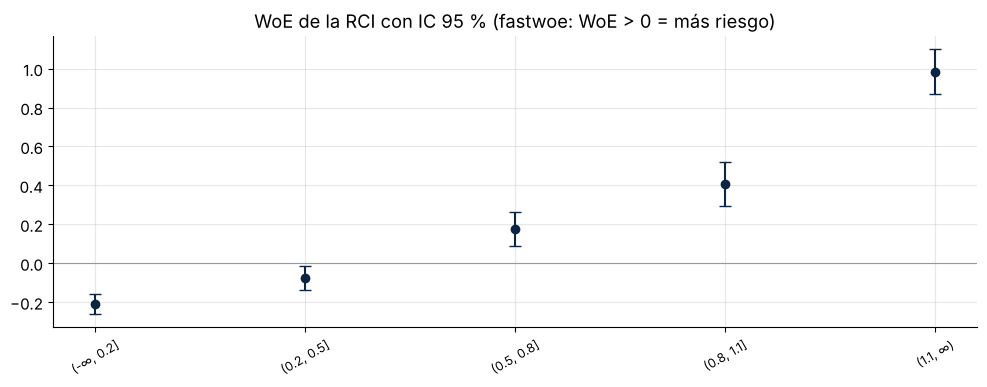

In [9]:
Xf = dev[["EXT_SOURCE_2", "EDAD", "RCI", "DAYS_EMPLOYED", "OCCUPATION_TYPE", "NAME_INCOME_TYPE"]].copy()
fw = FastWoe(binning_method="tree", tree_kwargs={"min_samples_leaf": 1000}, monotonic_cst={"EXT_SOURCE_2": -1, "RCI": 1, "EDAD": -1},
             special_codes=[365243], random_state=0)
fw.fit(Xf, dev.TARGET)
m = fw.get_mapping("RCI")
display(m[["category", "count", "event_rate", "woe", "woe_se", "woe_ci_lower", "woe_ci_upper"]].style.format(
    {"event_rate": "{:.2%}", "woe": "{:+.3f}", "woe_se": "{:.3f}", "woe_ci_lower": "{:+.3f}", "woe_ci_upper": "{:+.3f}"}))
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(m))
ax.errorbar(x, m.woe, yerr=[m.woe - m.woe_ci_lower, m.woe_ci_upper - m.woe], fmt="o", color=AZUL, capsize=4)
ax.axhline(0, color=GRIS, lw=.8); ax.set_xticks(x); ax.set_xticklabels(m.category, rotation=30, fontsize=9)
ax.set_title("WoE de la RCI con IC 95 % (fastwoe: WoE > 0 = más riesgo)"); plt.tight_layout(); plt.show()

**Lectura:** los tramos con pocos clientes tienen intervalos amplios. Si dos tramos adyacentes tienen intervalos que se solapan mucho, no hay evidencia de que su riesgo sea distinto: conviene fusionarlos.

### 3.2 IV con error estándar, test de significancia y sesgo de ruido
fastwoe calcula el error estándar del IV por el método delta y lo contrasta con $n_{ef} \cdot IV \sim \chi^2_{k-1}$ bajo la hipótesis de "sin poder predictivo", con $n_{ef} = n_{malos}\, n_{buenos} / (n_{malos} + n_{buenos})$. Bajo esa hipótesis, $E[IV] \approx (k-1)/n_{ef}$: **muchas categorías y pocos malos inflan el IV aunque la variable sea puro ruido**.

In [10]:
rng = np.random.default_rng(0)
Xr = dev[["NAME_INCOME_TYPE", "AGENCIA_ID"]].copy()
Xr["RUIDO_300_CATEGORIAS"] = rng.integers(0, 300, len(dev)).astype(str)          # variable sin ninguna relación con el incumplimiento
fw_r = FastWoe(random_state=0).fit(Xr, dev.TARGET)
iv = fw_r.get_iv_analysis()
n_b, n_g = dev.TARGET.sum(), (1 - dev.TARGET).sum(); n_ef = n_b * n_g / (n_b + n_g)
iv["IV_esperado_por_ruido"] = (iv.n_categories - 1) / n_ef
iv[["feature", "n_categories", "iv", "iv_se", "iv_ci_lower", "iv_ci_upper", "iv_pvalue", "iv_significance", "IV_esperado_por_ruido"]].style.format(
    {"iv": "{:.4f}", "iv_se": "{:.4f}", "iv_ci_lower": "{:.4f}", "iv_ci_upper": "{:.4f}", "iv_pvalue": "{:.3g}", "IV_esperado_por_ruido": "{:.4f}"})

,feature,n_categories,iv,iv_se,iv_ci_lower,iv_ci_upper,iv_pvalue,iv_significance,IV_esperado_por_ruido
1,AGENCIA_ID,180,0.1853,0.0148,0.1564,0.2143,0,Significant,0.0500
0,NAME_INCOME_TYPE,5,0.1380,0.0126,0.1133,0.1627,0,Significant,0.0011
2,RUIDO_300_CATEGORIAS,300,0.0810,0.0096,0.0623,0.0998,0.609,Not Significant,0.0836


**Lectura:** la variable de puro ruido con 300 categorías tiene un IV de ~0,08 ("débil" según la regla práctica), pero el test indica que **no es significativa**: su IV coincide con el esperado por azar. `AGENCIA_ID` tiene un IV mayor que su sesgo de ruido y sí es significativa. La regla "IV > 0,02" sin inferencia selecciona ruido en variables de alta cardinalidad.

### 3.3 WoE condicional: evitar el doble conteo de variables correlacionadas
Sumar WoE marginales supone independencia condicional (el supuesto *naive Bayes*). Con variables correlacionadas se **cuenta dos veces** la misma evidencia. fastwoe implementa la **regla de la cadena de Good**: el peso de cada variable se mide **dentro** de la población definida por las anteriores, y los pesos condicionales suman el score exacto.

In [11]:
d = pd.DataFrame({"pensionista": np.where(dev.DAYS_EMPLOYED == 365243, "si", "no"),
                  "mayor_55": np.where(dev.EDAD > 55, "si", "no")})
marg = FastWoe(random_state=0).fit(d, dev.TARGET)
cond = FastWoe(conditional=True, conditional_order=["pensionista", "mayor_55"], random_state=0).fit(d, dev.TARGET)
print(cond.export_text())
iv_c = cond.get_iv_analysis()
print("IV marginal:", marg.get_iv_analysis().set_index("feature").iv.round(4).to_dict())
print("IV condicional:", iv_c.set_index("feature").iv_conditional.round(4).to_dict())

Conditional WOE tree  ·  target: TARGET  ·  event rate = share of rows with TARGET = 1
Conditioning order: pensionista → mayor_55  ·  prior log-odds -2.353

                            W  95% interval           n  event rate  -0.97                  0 +0.23
root                                             45,092        8.7%
├── pensionista = no   +0.126  [+0.091, +0.160]  37,028        9.7%                         ┊  ●─
│   ├── mayor_55 = no  +0.071  [+0.034, +0.107]  30,741       10.4%                         ┊─●─
│   └── mayor_55 = si  -0.420  [-0.520, -0.321]   6,287        6.6%             ──●───      ┊
└── pensionista = si   -0.860  [-0.973, -0.747]   8,064        3.9%  ───●──                 ┊
    ├── mayor_55 = no  +0.196  [+0.159, +0.233]       1        0.0%                         ┊   ─○─  [fallback]
    └── mayor_55 = si  +0.000  [-0.113, +0.113]   8,063        3.9%                       ──●───
IV marginal: {'mayor_55': 0.112, 'pensionista': 0.1071}
IV condicional: {'mayor_55'

**Lectura:** "mayor de 55" tiene un IV marginal similar a "pensionista", pero **dado que el cliente es pensionista** casi no aporta evidencia adicional (todos los pensionistas son mayores). Sumar ambos WoE marginales duplicaría la evidencia de "edad avanzada". El orden de condicionamiento cambia la atribución entre variables, no el score total: debe fijarse con criterio de negocio.

### 3.4 Alta cardinalidad: `WoePreprocessor` y categorías no vistas

In [12]:
pre = WoePreprocessor(max_categories=40, min_count=100)
Xe_dev = pre.fit_transform(dev[["EMPLEADOR_ID"]]); Xe_oot = pre.transform(oot[["EMPLEADOR_ID"]])
display(pre.get_reduction_summary(dev[["EMPLEADOR_ID"]]))
fw_e = FastWoe(unseen="prior", random_state=0).fit(Xe_dev, dev.TARGET)
display(fw_e.get_iv_analysis()[["feature", "n_categories", "iv", "iv_ci_lower", "iv_ci_upper", "iv_significance"]])
print(f"AUC fuera de tiempo solo con EMPLEADOR_ID (WoE): {roc_auc_score(y_oot, fw_e.predict_proba(Xe_oot)[:, 1]):.3f}")

,feature,original_categories,kept_categories,reduction_pct
0,EMPLEADOR_ID,2962,52,98.2444


,feature,n_categories,iv,iv_ci_lower,iv_ci_upper,iv_significance
0,EMPLEADOR_ID,53,0.1442,0.1185,0.1698,Significant


AUC fuera de tiempo solo con EMPLEADOR_ID (WoE): 0.551


### 3.5 Intervalos de confianza para la predicción
`predict_ci` propaga la incertidumbre del WoE de cada variable hasta la probabilidad del cliente (bajo el supuesto de independencia entre variables). Es útil para identificar clientes cuya PD es incierta (tramos con poca historia) y enviarlos a revisión humana.

In [13]:
Xo = oot[Xf.columns].copy()
ci = np.asarray(fw.predict_ci(Xo.head(8)))
p = fw.predict_proba(Xo.head(8))[:, 1]
pd.DataFrame({"PD": p, "IC_inferior": ci[:, 0], "IC_superior": ci[:, 1]}).assign(ancho=lambda t: t.IC_superior - t.IC_inferior).style.format("{:.2%}")

,PD,IC_inferior,IC_superior,ancho
0,12.92%,10.86%,15.31%,4.45%
1,2.22%,1.72%,2.85%,1.12%
2,0.64%,0.51%,0.79%,0.28%
3,9.88%,8.02%,12.13%,4.12%
4,0.20%,0.16%,0.25%,0.09%
5,1.42%,1.14%,1.76%,0.63%
6,1.47%,1.12%,1.92%,0.79%
7,15.30%,11.27%,20.43%,9.16%


## 4. Estabilidad de los tramos y comparación de enfoques
Un binning que funciona en desarrollo pero cambia fuera de tiempo no sirve. Revisamos el PSI de la distribución por tramos y la tasa de malos por tramo en 2025.

,IV_dev,PSI_tramos
variable,,
EXT_SOURCE_2,0.6655,0.0155
EXT_SOURCE_3,0.4865,0.0077
EXT_SOURCE_1,0.2083,0.0019
EDAD,0.1744,0.0009
DAYS_EMPLOYED,0.1718,0.0006
NAME_INCOME_TYPE,0.1380,0.0004
AGENCIA_ID,0.1303,0.0009
OCCUPATION_TYPE,0.1050,0.0001
RCI,0.0909,0.0007


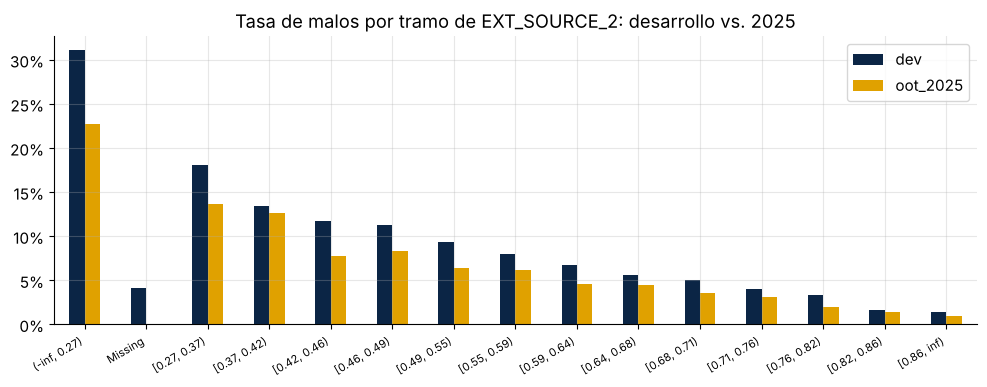

In [14]:
def psi(e, a):
    e, a = np.clip(e, 1e-6, None), np.clip(a, 1e-6, None)
    return np.sum((a - e) * np.log(a / e))
sel = bp.get_support(names=True)
bins_dev = bp.transform(dev[VARS], metric="bins"); bins_oot = bp.transform(oot[VARS], metric="bins")
estab = []
for v in sel:
    e = bins_dev[v].value_counts(normalize=True); a = bins_oot[v].value_counts(normalize=True).reindex(e.index).fillna(0)
    estab.append({"variable": v, "IV_dev": resumen.set_index("name").loc[v, "iv"], "PSI_tramos": psi(e.values, a.values)})
display(pd.DataFrame(estab).set_index("variable").sort_values("IV_dev", ascending=False).style.format("{:.4f}"))

v = "EXT_SOURCE_2"
comp = pd.DataFrame({"dev": pd.Series(y_dev).groupby(bins_dev[v].values).mean(), "oot_2025": pd.Series(y_oot).groupby(bins_oot[v].values).mean()})
comp.plot(kind="bar", color=[AZUL, ORO], figsize=(10, 4)); plt.title(f"Tasa de malos por tramo de {v}: desarrollo vs. 2025"); plt.xticks(rotation=30, ha="right", fontsize=8)
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y_, _: f"{y_:.0%}")); plt.tight_layout(); plt.show()

In [15]:
# Comparación: logística sobre WoE de optbinning vs. fastwoe (naive Bayes) vs. logística sobre WoE de fastwoe
X_bp_dev = bp.transform(dev[VARS], metric="woe"); X_bp_oot = bp.transform(oot[VARS], metric="woe")
lr_bp = LogisticRegression(C=1e6, max_iter=3000).fit(X_bp_dev, y_dev)
cols_fw = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3", "EDAD", "RCI", "DAYS_EMPLOYED", "NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE", "OCCUPATION_TYPE", "CODE_GENDER", "FLAG_OWN_CAR", "REGION_RATING_CLIENT", "AGENCIA_ID"]
fw_all = FastWoe(binning_method="tree", tree_kwargs={"min_samples_leaf": 800}, special_codes=[365243], random_state=0).fit(dev[cols_fw], dev.TARGET)
W_dev, W_oot = fw_all.transform(dev[cols_fw]), fw_all.transform(oot[cols_fw])
lr_fw = LogisticRegression(C=1e6, max_iter=3000).fit(W_dev, y_dev)
pd.DataFrame({"AUC fuera de tiempo": {
    f"optbinning + logística ({len(sel)} variables seleccionadas)": roc_auc_score(y_oot, lr_bp.predict_proba(X_bp_oot)[:, 1]),
    "fastwoe: suma de WoE (naive Bayes)": roc_auc_score(y_oot, fw_all.predict_proba(oot[cols_fw])[:, 1]),
    "fastwoe + logística": roc_auc_score(y_oot, lr_fw.predict_proba(W_oot)[:, 1])}}).style.format("{:.4f}")

,AUC fuera de tiempo
optbinning + logística (12 variables seleccionadas),0.7722
fastwoe: suma de WoE (naive Bayes),0.7636
fastwoe + logística,0.7727


**Lectura:** la logística sobre WoE supera a la suma directa de WoE porque **re-pondera** las variables y corrige parte del doble conteo entre variables correlacionadas. Ambas librerías se complementan: **optbinning** para diseñar tramos con restricciones de negocio y producir el scorecard (sesión 4); **fastwoe** para cuantificar la incertidumbre del WoE y del IV, y para el tratamiento condicional de variables correlacionadas.

| | optbinning | fastwoe |
|---|---|---|
| Fortaleza | Optimización con restricciones (CP/MIP), monotonicidad flexible, 2D, scorecard y monitoreo | Inferencia: SE e IC del WoE, IV con test, WoE condicional, IC de la predicción |
| Convención WoE | ln(%buenos / %malos): + = menos riesgo | log-odds relativo de incumplir: + = más riesgo |
| Ideal para | Construir y documentar el scorecard | Validar, seleccionar sin ruido, explicar con incertidumbre |

## 5. Ejercicios
1. Fuerza `monotonic_trend="peak"` en `RCI`. ¿Tiene sentido de negocio? ¿Cuánto IV gana o pierde?
2. Repite el ejercicio del ruido con 30 y con 3 000 categorías. ¿Cómo escala el sesgo del IV?
3. Cambia el orden del WoE condicional (`mayor_55` primero). ¿Qué cambia y qué no?
4. Con `OptimalBinning2D`, prueba `EXT_SOURCE_3 × EDAD`. ¿La interacción aporta IV respecto a las variables por separado?